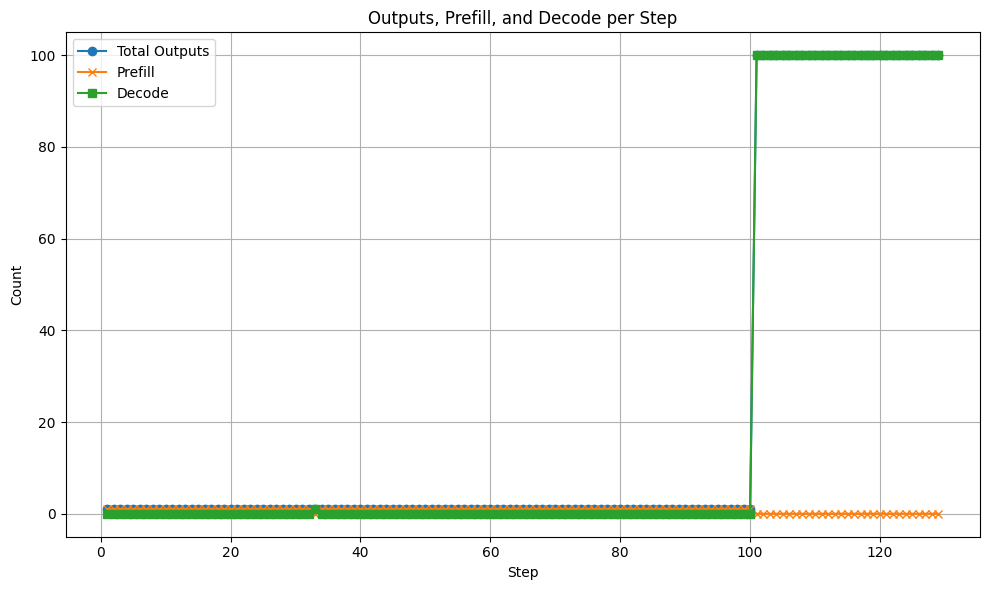

In [4]:
import re
import matplotlib.pyplot as plt

# Read file
with open("out_infinite_chunked_prefill", "r") as f:
    lines = f.readlines()

steps = []
outputs = []
prefill_counts = []
decode_counts = []

i = 0
step = 0
while i < len(lines):
    match = re.search(r"Number of outputs in this step:\s+(\d+)", lines[i])
    if match:
        k = int(match.group(1))
        step += 1
        steps.append(step)
        outputs.append(k)

        prefill, decode = 0, 0
        # Look at next k lines
        for j in range(i + 1, min(i + 1 + k, len(lines))):
            if "prefill" in lines[j].lower():
                prefill += 1
            else:
                decode += 1

        prefill_counts.append(prefill)
        decode_counts.append(decode)

        i += k  # skip past those k lines
    else:
        i += 1

# --- Plotting ---
plt.figure(figsize=(10, 6))
plt.plot(steps, outputs, marker='o', label="Total Outputs")
plt.plot(steps, prefill_counts, marker='x', label="Prefill")
plt.plot(steps, decode_counts, marker='s', label="Decode")
plt.xlabel("Step")
plt.ylabel("Count")
plt.title("Outputs, Prefill, and Decode per Step")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("../../results/vllm_batch_outputs.png")
plt.show()


In [3]:
import torch
import time

start_event = torch.cuda.Event(enable_timing=True)
end_event = torch.cuda.Event(enable_timing=True)

# Host tensors
xh = torch.randn(5000, 5000)
yh = torch.randn(5000, 5000)

# CPU timer start
cpu_start = time.perf_counter()
start_event.record()
# Copy to GPU
x = xh.to("cuda")
y = yh.to("cuda")

# GPU compute

z = x @ y
end_event.record()

torch.cuda.synchronize()
cpu_end = time.perf_counter()

gpu_time_ms = start_event.elapsed_time(end_event)
cpu_time_ms = (cpu_end - cpu_start) * 1000

print(f"GPU kernel execution time : {gpu_time_ms:.3f} ms")
print(f"Total elapsed CPU time    : {cpu_time_ms:.3f} ms")
print(f"Transfer + overhead       : {cpu_time_ms - gpu_time_ms:.3f} ms")


GPU kernel execution time : 40.374 ms
Total elapsed CPU time    : 40.563 ms
Transfer + overhead       : 0.189 ms
